### [GALT] Vežba 3: Raspodela zvezda u Galaksiji

### <font color='yellow'> Ideja vežbe: Određivanje Galaktičkog potencijala i rotacione krive iz sintetičke populacije zvezda. </font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod

U prošloj vežbi, generisali smo sintetičku populaciju zvezda koja prati Salpeterov zakon:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
U nastavku smo pretpostavili da su zvezde ravnomerno raspoređene u sferi, da bismo analizirali Malmkvisnovu neobjektivnost. Međutim, mi znamo da raspodela zvezda (i generalno materije) u Galaksiji nije uniformna.

Pretpostavimo da je prostorna gustina zvezda opisana eksponencijalnim diskom:

$$
\rho(R,z)=\rho_0\exp(-R/R_d)\exp(-|z|/z_d),
$$

gde su R i z cilindrične koordinate, $R_d$ i $z_d$ skala diska i visinska skala. Ugao $\varphi$ je uniforman na $(0,2\pi)$.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

##### <font color="green">1. Semplovati 100 000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Ovo je iz prethodne vežbe.)</font>

Broj simuliranih zvezda: 100000
Najmanja masa: 0.0800009510357377
Najveća masa: 132.18269032738948
Prosečna masa: 0.29063651752129255


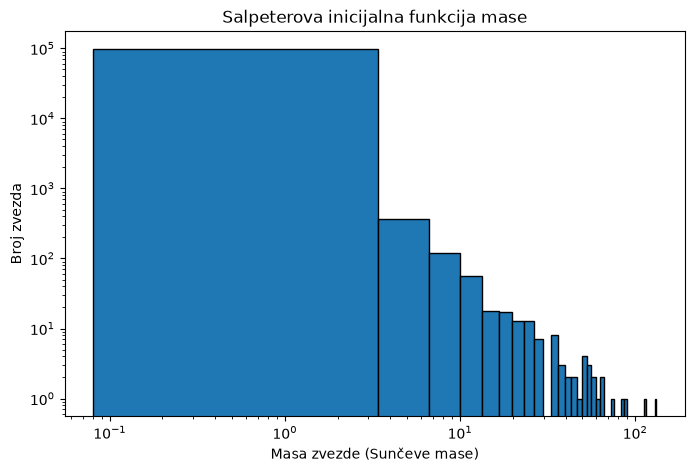

In [ ]:

N = 100000
M_min = 0.08
M_max = 200
alpha = 2.35

u = np.random.uniform(0, 1, N)

mase = (M_min**(1-alpha) + u * (M_max**(1-alpha) - M_min**(1-alpha)))**(1/(1-alpha))

print("Broj simuliranih zvezda:", len(mase))
print("Najmanja masa:", np.min(mase))
print("Najveća masa:", np.max(mase))
print("Prosečna masa:", np.mean(mase))

# Histogram za raspodelu masa zvezda
plt.figure(figsize=(8,5))
plt.hist(mase, bins=40, edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Masa zvezde (Sunčeve mase)')
plt.ylabel('Broj zvezda')
plt.title('Salpeterova inicijalna funkcija mase')
plt.show()

<span style="color: pink;">Dobijeni histogram pokazuje da je najviše malih zvezda, dok je broj zvezda velikih masa mnogo manji, što je u skladu sa Salpeterovim zakonom (kao kod prethodne vežbe, samo 100k zvezda umesto 10k zvezda).</span>

##### <font color="green">2. Semplovati cilindrične koordinate za svaku zvezdu. (Uzeti, npr. $R_d$ = 3kpc i $z_d$ = 0.2kpc.) Objasniti kako se semplovanje vrši. </font>

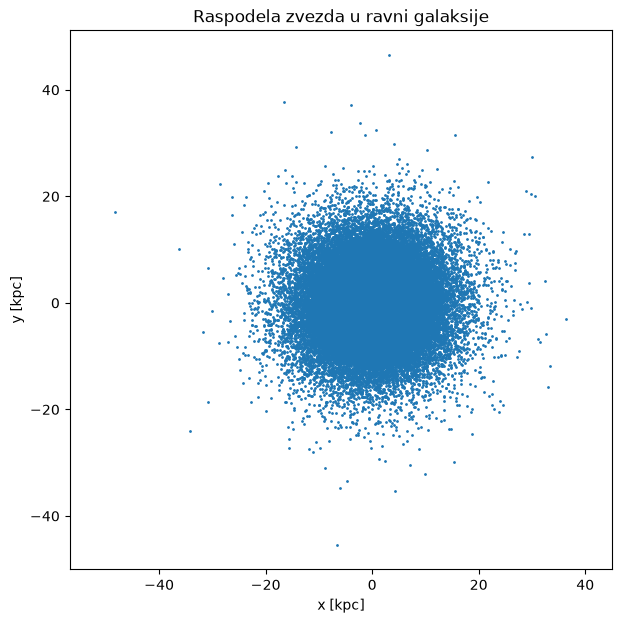

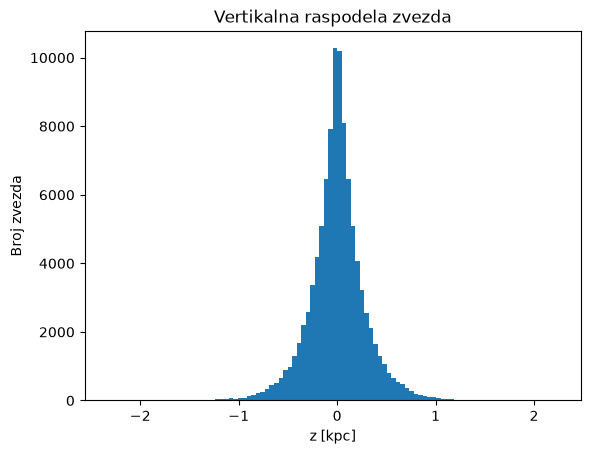

In [ ]:
Rd = 3.0
zd = 0.2

# radijalne koordinate
u1 = np.random.uniform(0, 1, N)
u2 = np.random.uniform(0, 1, N)

R = -Rd * np.log(u1 * u2)

# vertikalne koordinate
u3 = np.random.uniform(0, 1, N)

z_abs = -zd * np.log(u3)

# nasumično biranje da li je z pozitivno ili negativno
sign = np.random.choice([-1, 1], N)

z = sign * z_abs

# Azimut
phi = np.random.uniform(0, 2*np.pi, N)

# prebacivanje u Dekartove koordinate
x = R * np.cos(phi)
y = R * np.sin(phi)


plt.figure(figsize=(7, 7))
plt.scatter(x, y, s=1)
plt.xlabel("x [kpc]")
plt.ylabel("y [kpc]")
plt.title("Raspodela zvezda u ravni galaksije")
plt.axis("equal")
plt.show()

plt.figure()
plt.hist(z, bins=100)
plt.xlabel("z [kpc]")
plt.ylabel("Broj zvezda")
plt.title("Vertikalna raspodela zvezda")
plt.show()



<span style="color: pink;">Prostorna raspodela zvezda generisana je prema eksponencijalnom modelu diska. Radijalna koordinata semplovana je iz raspodele koja sadrži faktor R, zbog cilindričnog zapreminskog elementa. Vertikalna koordinata semplovana je iz simetrične eksponencijalne raspodele, dok je azimut uniformno raspoređen između 0 i 2π. Onda je dobijena populacija zvezda koja prati zadatu prostornu gustinu.</span>

##### <font color="green">3. Prikazati raspodelu zvezda u 3D, kao i (R, z) i (x, y) ravni.</font>

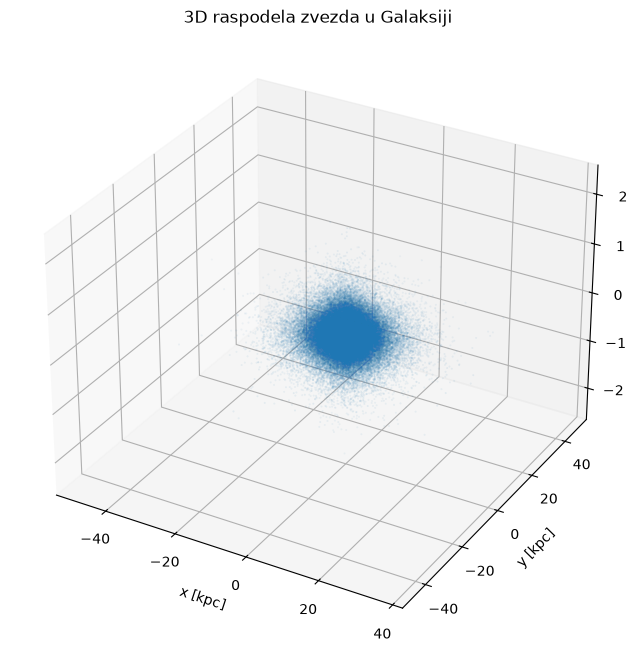

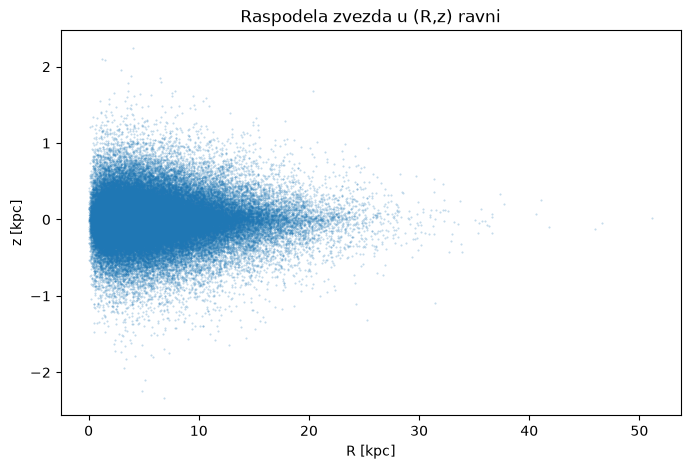

In [23]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(
    x, y, z,
    s=0.2,
    alpha=0.3
)
ax.set_xlabel('x [kpc]')
ax.set_ylabel('y [kpc]')
ax.set_zlabel('z [kpc]')
ax.set_title('3D raspodela zvezda u Galaksiji')
plt.show()




plt.figure(figsize=(8, 5))
plt.scatter(R, z, s=0.2, alpha=0.3)
plt.xlabel('R [kpc]')
plt.ylabel('z [kpc]')
plt.title('Raspodela zvezda u (R,z) ravni')
plt.show()

<span style="color: pink;">Na 3D prikazu uočava se diskasta struktura populacije zvezda. U (x, y) (na 3D prikazu9) zvezde su raspoređene približno simetrično oko centra galaksije, pri čemu je njihova koncentracija najveća u centralnim oblastima. U (R, z) se vidi da gustina zvezda opada sa porastom radijalnog rastojanja i apsolutne visine. Dobijeni prikazi odgovaraju očekivanoj eksponencijalnoj raspodeli.</span>

Potrebno je odraditi normalizaciju, tako da celi disk ima masu $M_{disk}$. Uzeti, npr. $M_{disk}=5\cdot 10^{10}M_\odot$. Dakle, ako integralimo prethodno zadatku gustinu po zapremini, možemo da odredimo vrednost $\rho_0$. 

In [ ]:
#Normalizacija gustine diska
Mdisk = 5e10  # Msun     - masa sunca i Mdisk - masa diska
Rd = 3.0      # kpc
zd = 0.2      # kpc

rho0 = Mdisk / (4 * np.pi * Rd**2 * zd)

print("Centralna gustina rho0 =", rho0, "Msun/kpc^3")

Centralna gustina rho0 = 2210485320.7207685 Msun/kpc^3


<span style="color: pink;">Dobijena vrednost rho0 pokazuje da je gustina najveća u centru galaksije, dok se sa udaljavanjem od centra (R) i udaljavanjem od galaktičke ravni (z) gustina eksponencijalno smanjuje.</span>

##### <font color="green">4. Izračunati $\rho_0$.</font>

In [25]:
rho = rho0 * np.exp(-R/Rd) * np.exp(-np.abs(z)/zd)

print("Prvih 10 vrednosti gustine:")
print(rho[:10])

Prvih 10 vrednosti gustine:
[3.03986253e+08 1.77732230e+08 3.92756362e+06 1.09000737e+08
 2.15418286e+07 1.02465820e+09 9.62398933e+07 2.08587593e+08
 3.79788881e+07 3.98245795e+08]


<span style="color: pink;">Dobijeni rezultati pokazuju da gustina zavisi od radijalne udaljenosti od centra galaksije i visine u odnosu na galaktičku ravan. Gustina je najveća u centru galaksije, u ravni diska, a  opada sa povećanjem udaljenosti R i apsolutne vrednosti visine z. </span>

Dalje, koristeći Poasonovu jednačinu: 

$$\nabla^2 \Phi = 4\pi G\rho$$

možemo da odredimo Galaktički potencijal koji odgovara zadatoj raspodeli gustine.

Poasonova jednačina u cilindričnim koordinatama:

$$ \frac{1}{R}\frac{\partial}{\partial R}
\left(R\frac{\partial\Phi}{\partial R}\right)
+\frac{\partial^2\Phi}{\partial z^2}
=4\pi G\rho(R,z).
$$

Koristiti metodu konačnih razlika na dvodimenzionalnoj mreži $(R,z)$, za oblast $0\leq R\leq30\mathrm{kpc}$ i $-10\leq z\leq10\mathrm{kpc}$.

Primeniti sledeće granične uslove:

Na spoljnim granicama oblasti pretpostaviti da se potencijal približava potencijalu tačkaste mase ukupne mase diska:

$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+z^2}}.
$$

Na osi simetrije (R=0) primeniti uslov:

$$
\left.\frac{\partial\Phi}{\partial R}\right|_{R=0}=0.
$$

U nastavku je napisana funkcija solve_poisson koja numerički rešava ovaj problem.

In [4]:
def solve_poisson(rho, R, z, M, G):

    # broj tačaka numeričke mreže u R i z pravcu
    NR = len(R)
    NZ = len(z)

    # korak
    dR = R[1] - R[0]
    dz = z[1] - z[0]

    # na spoljnim granicama unapred zadajemo potencijal, pa ne moramo da ga racunamo kao nepoznatu
    nR = NR - 1
    nZ = NZ - 2

    # ukupan broj tačaka u kojima računamo vrednosti potencijala
    N = nR * nZ

    # 2D mrežu (i,j) preslikavamo u 1D indeks k, jer sistem rešavamo u obliku matrice A i vektora b
    def idx(i, j):
        return i * nZ + (j - 1)

    # formiramo praznu matricu A
    # koristimo lil_matrix jer je većina elemenata matrice nula
    A = lil_matrix((N, N))

    # desna strana Poasonove jednacine: 4*pi*G*rho
    b = (4 * np.pi * G * rho[:nR, 1:-1]).ravel().copy()

    # kreiramo 2D mrežu koordinata
    RR, ZZ = np.meshgrid(R, z, indexing="ij")

    # na spoljnim granicama oblasti potencijal aproksimiramo potencijalom tačkaste mase ukupne mase M
    # kao što piše iznad u graničnim uslovima, imamo ovo +1e-30 da ne bi došlo do deljenja sa 0 
    phi_boundary = -G * M / np.sqrt(RR**2 + ZZ**2 + 1e-30)

    # prolazimo kroz sve tačke u kojima je potencijal nepoznat
    for i in range(nR):
        for j in range(1, NZ - 1):

            # 1D indeks trenutne tačke
            k = idx(i, j)

            # -----------------------------------------
            # DRUGI IZVOD PO Z
            # -----------------------------------------

            # Drugi izvod po z aproksimiramo metodom konacnih razlika:
            #
            # d^2Phi/dz^2 ~
            # (Phi[i,j+1] - 2*Phi[i,j] + Phi[i,j-1]) / dz^2

            A[k, k] += -2 / dz**2

            # dodajemo doprinose susednih tačaka u z pravcu
            for jj in (j - 1, j + 1):

                if 1 <= jj <= NZ - 2:

                    # ako je susedna tačka unutar oblasti
                    # nepoznatih vrednosti, dodajemo je u matricu A
                    A[k, idx(i, jj)] += 1 / dz**2

                else:

                    # ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= phi_boundary[i, jj] / dz**2

            # -----------------------------------------
            # RADIJALNI DEO POASONOVE JEDNACINE
            # -----------------------------------------

            if i == 0:

                # Na osi R = 0 izraz 1/R nije definisan.
                # Zbog osne simetrije važi dPhi/dR = 0 na R = 0.
                # Koristimo posebnu aproksimaciju radijalnog operatora
                # na samoj osi.

                A[k, k] += -4 / dR**2
                A[k, idx(1, j)] += 4 / dR**2

            else:

                # Za R > 0 koristimo aproksimaciju konačnih razlika
                Ri = R[i]

                # koeficijenti uz potencijal u susednim radijalnim tackama R[i+1] i R[i-1].
                cp = 1 / dR**2 + 1 / (2 * Ri * dR)
                cm = 1 / dR**2 - 1 / (2 * Ri * dR)

                # koeficijent uz potencijal u trenutnoj tački
                A[k, k] += -2 / dR**2

                # doprinos unutršnje susedne tacke R[i-1]
                A[k, idx(i - 1, j)] += cm

                # doprinos susedne tacke R[i+1]
                if i + 1 < nR:

                    #ako je tačka unutar oblasti nepoznatih vrednosti, njen doprinos dodajemo u matricu A
                    A[k, idx(i + 1, j)] += cp

                else:

                    #  ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= cp * phi_boundary[i + 1, j]

    # -----------------------------------------
    # REŠAVANJE SISTEMA LINEARNIH JEDNAČINA
    # -----------------------------------------

    # Nakon diskretizacije Poasonove jednačine dobijamo sistem:
    #
    # A * Phi = b
    #
    # Funkcija spsolve numerički rešava ovaj sistem.
    # Rezultat je vektor vrednosti potencijala.
    #
    # zatim ga vraćamo u oblik 2D mreže (nR, nZ).
    phi_inner = spsolve(A.tocsr(), b).reshape(nR, nZ)

    # -----------------------------------------
    # REKONSTRUKCIJA MATRICE POTENCIJALA
    # -----------------------------------------

    # kreiramo matricu u kojoj ce biti sačuvane vrednosti potencijala u svim tačkama prvobitne mreže
    Phi = np.empty((NR, NZ))

    # na spoljašnjim granicama imamo unapred zadate vrednosti potencijala
    Phi[-1, :] = phi_boundary[-1, :]
    Phi[:, 0] = phi_boundary[:, 0]
    Phi[:, -1] = phi_boundary[:, -1]

    # unutrašnje vrednosti popunjavamo numeričkim rešenjem
    Phi[:nR, 1:-1] = phi_inner

    # funkcija vraća matricu gravitacionog potencijala Phi(R,z)
    return Phi

Pogledati kako funkcija radi i ne koristiti ju kao black-box. 

##### <font color="green">5. Pozivajući solve_possion funkciju, rešiti Poasonovu jednačinu i prikazati 2D mapu potencijala.</font>

Ako znamo potencijal, brzinu rotacije možemo odrediti koristeći izraz:
$$ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $$

##### <font color="green">6. Koristeći prethodni izraz, prikazati rotacionu krivu. </font>

##### <font color="green">7. Odrediti brzinu Sunca iz ove rotacione krive i uporediti sa prihvaćenom vrednošću. </font> 

##### <font color="green">8. Kako se menja rotaciona kriva ako je ukupna masa diska dva puta veća, z nepromenjene vrednosti $R_d$ i $z_d$. </font> 